<a href="https://colab.research.google.com/github/Anjali-4191/PROJECT_MODEL/blob/main/homeprices.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ==========================================
# STEP 1: IMPORT LIBRARIES
# ==========================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import os
import glob

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# ==========================================
# STEP 2: LOAD DATASET
# ==========================================

file_path = '/content/homeprices.csv'

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Shape of dataset:", df.shape)

df.head()

Dataset loaded successfully!
Shape of dataset: (5, 2)


,area,price
0,2600,550000
1,3000,565000
2,3200,610000
3,3600,680000
4,4000,725000


In [4]:
# ==========================================
# STEP 3: STATISTICAL SUMMARY
# ==========================================

df.describe(include='all')

,area,price
count,5.000000,5.000000
mean,3280.000000,626000.000000
std,540.370243,74949.983322
min,2600.000000,550000.000000
25%,3000.000000,565000.000000
50%,3200.000000,610000.000000
75%,3600.000000,680000.000000
max,4000.000000,725000.000000


In [5]:
# Check column names
print("Columns in dataset:")
print(df.columns.tolist())

Columns in dataset:
['area', 'price']


In [6]:
# ==========================================
# DISPLAY FIRST AND LAST RECORDS
# ==========================================

print("First 5 records:")
display(df.head(5))

print("\nLast 5 records:")
display(df.tail(5))

First 5 records:


,area,price
0,2600,550000
1,3000,565000
2,3200,610000
3,3600,680000
4,4000,725000



Last 5 records:


,area,price
0,2600,550000
1,3000,565000
2,3200,610000
3,3600,680000
4,4000,725000


In [7]:
rows, columns = df.shape

print("Total Rows:", rows)
print("Total Columns:", columns)

Total Rows: 5
Total Columns: 2


In [8]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
display(missing_values)

Missing values in each column:


,0
area,0
price,0


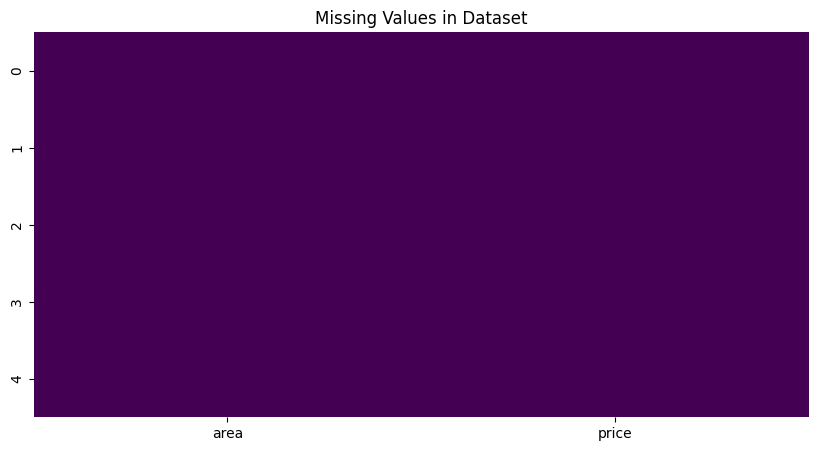

In [9]:
plt.figure(figsize=(10, 5))

sns.heatmap(df.isnull(),
            cbar=False,
            cmap='viridis')

plt.title("Missing Values in Dataset")
plt.show()


In [10]:
duplicate_count = df.duplicated().sum()

print("Total duplicate records:", duplicate_count)

Total duplicate records: 0


In [11]:
df[['area', 'price']].describe()

,area,price
count,5.000000,5.000000
mean,3280.000000,626000.000000
std,540.370243,74949.983322
min,2600.000000,550000.000000
25%,3000.000000,565000.000000
50%,3200.000000,610000.000000
75%,3600.000000,680000.000000
max,4000.000000,725000.000000


In [12]:
print("Unique Areas:", df['area'].nunique())
print("Unique Prices:", df['price'].nunique())

Unique Areas: 5
Unique Prices: 5


In [14]:
df_clean = df.copy()

print("Working copy created.")


Working copy created.


In [15]:
df_clean.columns = df_clean.columns.str.strip()

print(df_clean.columns.tolist())

['area', 'price']


In [16]:
before_duplicates = len(df_clean)

df_clean = df_clean.drop_duplicates()

after_duplicates = len(df_clean)

print("Records before removing duplicates:", before_duplicates)
print("Records after removing duplicates:", after_duplicates)
print("Duplicates removed:", before_duplicates - after_duplicates)

Records before removing duplicates: 5
Records after removing duplicates: 5
Duplicates removed: 0


In [17]:
print("Missing values before handling:")
display(df_clean.isnull().sum())



Missing values before handling:


,0
area,0
price,0


In [18]:
# Check missing values
print("Missing values before handling:")
print(df_clean.isnull().sum())

# Fill missing area with median
df_clean['area'] = df_clean['area'].fillna(df_clean['area'].median())

# Fill missing price with median
df_clean['price'] = df_clean['price'].fillna(df_clean['price'].median())

print("\nMissing values handled.")

Missing values before handling:
area     0
price    0
dtype: int64

Missing values handled.


In [19]:
# Convert Area into numeric
df_clean['area'] = pd.to_numeric(
    df_clean['area'], errors='coerce'
)

# Convert Price into numeric
df_clean['price'] = pd.to_numeric(
    df_clean['price'], errors='coerce'
)

print("Data types after conversion:")
print(df_clean.dtypes)

Data types after conversion:
area     int64
price    int64
dtype: object


In [20]:
df_clean = df_clean.dropna(subset=['area', 'price'])

print("Invalid values removed.")

print("Remaining records:", df_clean.shape)

Invalid values removed.
Remaining records: (5, 2)


In [21]:
print("Total Houses:", len(df_clean))

print("Unique House Areas:", df_clean['area'].nunique())

print("Unique House Prices:", df_clean['price'].nunique())

print("Minimum House Price:", df_clean['price'].min())

print("Maximum House Price:", df_clean['price'].max())

Total Houses: 5
Unique House Areas: 5
Unique House Prices: 5
Minimum House Price: 550000
Maximum House Price: 725000


In [22]:
# ==========================================
# STEP: CREATE CLEAN HOUSE PRICE DATASET
# ==========================================

df_sales = df_clean[
    (df_clean['area'] > 0) &
    (df_clean['price'] > 0)
].copy()

print("House price dataset created.")
print("Original records:", len(df))
print("Valid house records:", len(df_sales))

House price dataset created.
Original records: 5
Valid house records: 5


In [23]:
# ==========================================
# OUTLIER DETECTION IN HOUSE PRICE
# ==========================================

Q1 = df_sales['price'].quantile(0.25)
Q3 = df_sales['price'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_sales['PriceOutlier'] = (
    (df_sales['price'] < lower_bound) |
    (df_sales['price'] > upper_bound)
)

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

print("Price Outliers:", df_sales['PriceOutlier'].sum())

Lower Bound: 392500.0
Upper Bound: 852500.0
Price Outliers: 0


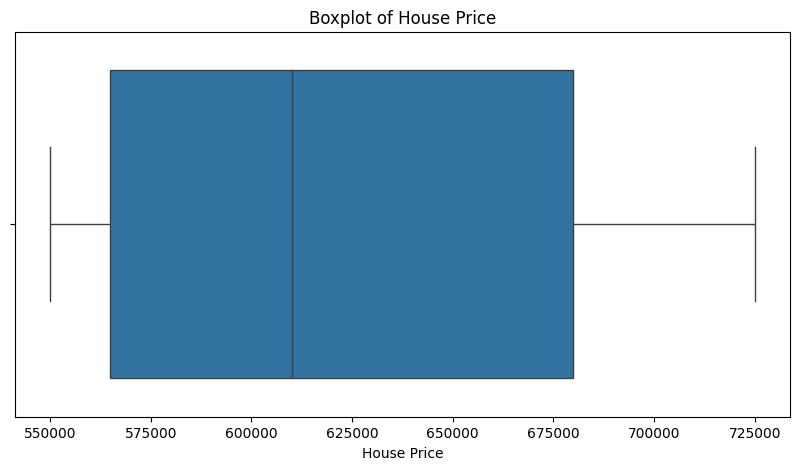

In [24]:
# ==========================================
# BOXPLOT OF HOUSE PRICE
# ==========================================

plt.figure(figsize=(10, 5))

sns.boxplot(x=df_sales['price'])

plt.title("Boxplot of House Price")
plt.xlabel("House Price")
plt.show()

** DATA INTREGATION**

In [25]:
# ==========================================
# CREATE HOUSE DATA
# ==========================================

house_data = df_sales[
    ['area', 'price']
].drop_duplicates()

house_data = house_data.dropna(subset=['area', 'price'])

house_data.head()

,area,price
0,2600,550000
1,3000,565000
2,3200,610000
3,3600,680000
4,4000,725000


In [26]:
product_data = df_sales[
    ['area', 'price']
].drop_duplicates(subset=['area'])

product_data.head()

,area,price
0,2600,550000
1,3000,565000
2,3200,610000
3,3600,680000
4,4000,725000


In [28]:
integrated_data = pd.merge(
    df_sales,
    product_data,
    on='area',
    how='left',
    suffixes=('', '_Product')
)

print("Integrated dataset created.")
display(integrated_data.head())

Integrated dataset created.


,area,price,PriceOutlier,price_Product
0,2600,550000,False,550000
1,3000,565000,False,565000
2,3200,610000,False,610000
3,3600,680000,False,680000
4,4000,725000,False,725000


In [29]:
print("House dataset rows:", len(df_sales))
print("Integrated dataset rows:", len(integrated_data))

print("Missing Area:", integrated_data['area'].isnull().sum())
print("Missing Price:", integrated_data['price'].isnull().sum())

House dataset rows: 5
Integrated dataset rows: 5
Missing Area: 0
Missing Price: 0


In [30]:
# Calculate total house price

df_sales['TotalAmount'] = df_sales['price']

print("Total house price calculated successfully!")

display(
    df_sales[
        ['area', 'price', 'TotalAmount']
    ].head(10)
)

Total house price calculated successfully!


,area,price,TotalAmount
0,2600,550000,550000
1,3000,565000,565000
2,3200,610000,610000
3,3600,680000,680000
4,4000,725000,725000


In [31]:
# Calculate total house amount

df_sales['TotalAmount'] = df_sales['price']

print("Total house amount calculated successfully!")

display(
    df_sales[
        ['area', 'price', 'TotalAmount']
    ].head(10)
)

Total house amount calculated successfully!


,area,price,TotalAmount
0,2600,550000,550000
1,3000,565000,565000
2,3200,610000,610000
3,3600,680000,680000
4,4000,725000,725000


In [32]:
# Extract house price features

df_sales['PricePerArea'] = (
    df_sales['price'] / df_sales['area']
)

df_sales['PriceCategory'] = np.where(
    df_sales['price'] >= df_sales['price'].median(),
    'High Price',
    'Low Price'
)

# Display extracted features

print("House features extracted successfully!")

display(
    df_sales[
        ['area', 'price', 'PricePerArea', 'PriceCategory']
    ].head(10)
)


House features extracted successfully!


,area,price,PricePerArea,PriceCategory
0,2600,550000,211.538462,Low Price
1,3000,565000,188.333333,Low Price
2,3200,610000,190.625000,High Price
3,3600,680000,188.888889,High Price
4,4000,725000,181.250000,High Price


In [33]:
# Calculate house-level metrics

house_metrics = df_sales.groupby('area').agg(
    TotalHouses=('price', 'count'),
    AveragePrice=('price', 'mean'),
    MinimumPrice=('price', 'min'),
    MaximumPrice=('price', 'max')
).reset_index()

print("House-level metrics calculated successfully!")

display(house_metrics.head(10))

House-level metrics calculated successfully!


,area,TotalHouses,AveragePrice,MinimumPrice,MaximumPrice
0,2600,1,550000.0,550000,550000
1,3000,1,565000.0,565000,565000
2,3200,1,610000.0,610000,610000
3,3600,1,680000.0,680000,680000
4,4000,1,725000.0,725000,725000


In [34]:
# Calculate house price metrics

house_metrics['PricePerArea'] = (
    house_metrics['AveragePrice'] / house_metrics['area']
)

house_metrics['AveragePricePerHouse'] = (
    house_metrics['AveragePrice'] / house_metrics['TotalHouses']
)

print("House price metrics calculated successfully!")

display(house_metrics.head(10))

House price metrics calculated successfully!


,area,TotalHouses,AveragePrice,MinimumPrice,MaximumPrice,PricePerArea,AveragePricePerHouse
0,2600,1,550000.0,550000,550000,211.538462,550000.0
1,3000,1,565000.0,565000,565000,188.333333,565000.0
2,3200,1,610000.0,610000,610000,190.625000,610000.0
3,3600,1,680000.0,680000,680000,188.888889,680000.0
4,4000,1,725000.0,725000,725000,181.250000,725000.0


In [35]:
# Calculate house price difference

house_metrics['PriceDifference'] = (
    house_metrics['MaximumPrice'] -
    house_metrics['MinimumPrice']
)

print("House price difference calculated successfully!")

display(
    house_metrics[
        ['area', 'MinimumPrice', 'MaximumPrice', 'PriceDifference']
    ].head(10)
)

House price difference calculated successfully!


,area,MinimumPrice,MaximumPrice,PriceDifference
0,2600,550000,550000,0
1,3000,565000,565000,0
2,3200,610000,610000,0
3,3600,680000,680000,0
4,4000,725000,725000,0


In [36]:
# Merge house metrics with house information

house_data = house_data.drop_duplicates(
    subset=['area']
)

house_data = pd.merge(
    house_data,
    house_metrics,
    on='area',
    how='left'
)

print("House data and metrics merged successfully!")

display(house_data.head(10))

House data and metrics merged successfully!


,area,price,TotalHouses,AveragePrice,MinimumPrice,MaximumPrice,PricePerArea,AveragePricePerHouse,PriceDifference
0,2600,550000,1,550000.0,550000,550000,211.538462,550000.0,0
1,3000,565000,1,565000.0,565000,565000,188.333333,565000.0,0
2,3200,610000,1,610000.0,610000,610000,190.625000,610000.0,0
3,3600,680000,1,680000.0,680000,680000,188.888889,680000.0,0
4,4000,725000,1,725000.0,725000,725000,181.250000,725000.0,0


In [42]:
# Display all column names

print(df.columns.tolist())

['area', 'price']


In [45]:
# Create home prices fact table

fact_home = df.copy()

fact_home.head()

,area,price
0,2600,550000
1,3000,565000
2,3200,610000
3,3600,680000
4,4000,725000
